In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("Titanic-Dataset.csv")
print("Initial shape:", df.shape)

Initial shape: (891, 12)


In [2]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [3]:
df["Age"] = df.groupby(["Pclass", "Sex"])["Age"].transform(
    lambda x: x.fillna(x.median())
)

In [4]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [5]:
df["HasCabin"] = df["Cabin"].notnull().astype(int)
df.drop(columns=["Cabin", "PassengerId", "Ticket", "Name"], inplace=True)

In [6]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

In [7]:
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df = pd.get_dummies(df, columns=["Embarked"], drop_first=True)

In [8]:
print("Final shape:", df.shape)
print(df.isnull().sum())
df.head()

Final shape: (891, 12)
Survived      0
Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
HasCabin      0
FamilySize    0
IsAlone       0
Embarked_Q    0
Embarked_S    0
dtype: int64


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,2,0,False,True
1,1,1,1,38.0,1,0,71.2833,1,2,0,False,False
2,1,3,1,26.0,0,0,7.9250,0,1,1,False,True
3,1,1,1,35.0,1,0,53.1000,1,2,0,False,True
4,0,3,0,35.0,0,0,8.0500,0,1,1,False,True


In [9]:
df.to_csv("titanic_cleaned.csv", index=False)
print("Saved cleaned dataset as titanic_cleaned.csv")

Saved cleaned dataset as titanic_cleaned.csv


In [10]:
X = df.drop("Survived", axis=1)
y = df["Survived"]

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [12]:
import lightgbm as lgb

model = lgb.LGBMClassifier(random_state=42)
model.fit(X_train, y_train)

[LightGBM] [Info] Number of positive: 268, number of negative: 444
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000177 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 210
[LightGBM] [Info] Number of data points in the train set: 712, number of used features: 11
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.376404 -> initscore=-0.504838
[LightGBM] [Info] Start training from score -0.504838
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf

,random_state,42
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001


In [13]:
from sklearn.metrics import accuracy_score, classification_report

preds = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, preds))
print(classification_report(y_test, preds))

Accuracy: 0.8156424581005587
              precision    recall  f1-score   support

           0       0.85      0.84      0.84       105
           1       0.77      0.78      0.78        74

    accuracy                           0.82       179
   macro avg       0.81      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



In [14]:
importances = model.feature_importances_
feature_names = X.columns

In [15]:
feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

feat_imp

,feature,importance
5,Fare,1138
2,Age,1023
7,FamilySize,99
1,Sex,97
10,Embarked_S,93
0,Pclass,68
3,SibSp,53
6,HasCabin,45
4,Parch,34
9,Embarked_Q,22


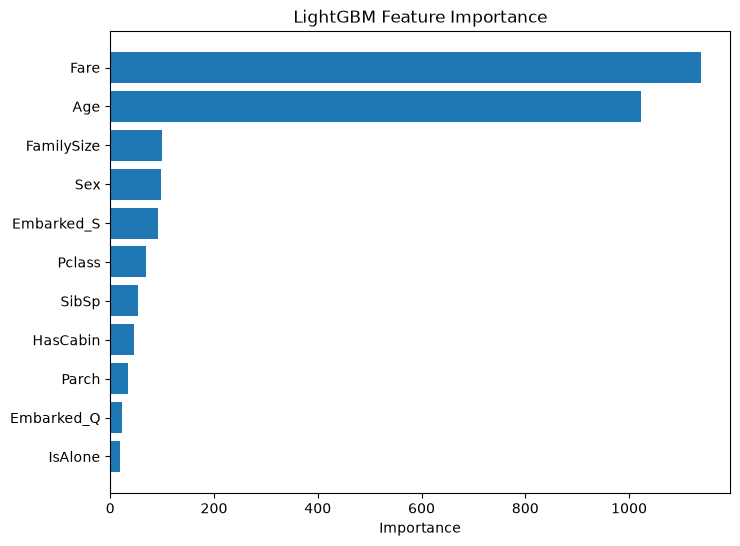

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.barh(feat_imp["feature"], feat_imp["importance"])
plt.xlabel("Importance")
plt.title("LightGBM Feature Importance")
plt.gca().invert_yaxis()  # highest importance at top
plt.show()

In [19]:
model_gain = lgb.LGBMClassifier(random_state=42, importance_type="gain")
model_gain.fit(X_train, y_train)

feat_imp_gain = pd.DataFrame({
    "feature": X.columns,
    "importance": model_gain.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_gain

[LightGBM] [Info] Number of positive: 268, number of negative: 444
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000155 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 210
[LightGBM] [Info] Number of data points in the train set: 712, number of used features: 11
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.376404 -> initscore=-0.504838
[LightGBM] [Info] Start training from score -0.504838
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf

,feature,importance
1,Sex,1213.298214
5,Fare,891.785015
2,Age,884.421709
0,Pclass,391.708973
6,HasCabin,129.665018
7,FamilySize,117.466222
10,Embarked_S,79.855272
3,SibSp,31.308906
4,Parch,29.804381
8,IsAlone,13.207959
